# Online Retail Exploratory Data Analysis (EDA)

## 1. Business Objective

### Objective
Analyze the Online Retail dataset to understand sales performance,
product purchasing patterns, customer behaviour, and trends over time.

### Key Questions
1. Which products generate the most revenue?
2. Which countries contribute the most sales?
3. How do sales change over time?
4. What are the customer purchasing patterns?
5. Are there unusual transactions or data-quality issues?
6. Which customers contribute the most revenue?

### Dataset
Source: UCI Machine Learning Repository — Online Retail

In [40]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_excel("../datasets/Online Retail.xlsx", sheet_name = "Online Retail")

In [3]:
print(df.head())
print("\n", "Shape of the data : ", df.shape)

  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

          InvoiceDate  UnitPrice  CustomerID         Country  
0 2010-12-01 08:26:00       2.55     17850.0  United Kingdom  
1 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
2 2010-12-01 08:26:00       2.75     17850.0  United Kingdom  
3 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
4 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  

 Shape of the data :  (541909, 8)


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


In [5]:
print("Checking missing values : \n", df.isnull().sum())

Checking missing values : 
 InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


In [6]:
print("Checking missing values percentage : \n", (df.isnull().mean() * 100).round(2))

Checking missing values percentage : 
 InvoiceNo       0.00
StockCode       0.00
Description     0.27
Quantity        0.00
InvoiceDate     0.00
UnitPrice       0.00
CustomerID     24.93
Country         0.00
dtype: float64


In [7]:
print("Checking duplicates : ")
print(df.duplicated().sum())

Checking duplicates : 
5268


In [8]:
df[df.duplicated(keep=False)].sort_values(
    by=["InvoiceNo", "StockCode"]
).head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
565,536412,21448,12 DAISY PEGS IN WOOD BOX,2,2010-12-01 11:49:00,1.65,17920.0,United Kingdom
578,536412,21448,12 DAISY PEGS IN WOOD BOX,1,2010-12-01 11:49:00,1.65,17920.0,United Kingdom


In [9]:
print("Recording orginal shape before removing duplicates : ")
print(df.shape)

Recording orginal shape before removing duplicates : 
(541909, 8)


In [10]:
df = df.drop_duplicates()
print("Checking the results after removing duplicates : ")
print("Duplicates count : ", df.duplicated().sum())
print("Shape of the Data Frame after removing duplicates : ", df.shape)

Checking the results after removing duplicates : 
Duplicates count :  0
Shape of the Data Frame after removing duplicates :  (536641, 8)


In [11]:
df.info()

<class 'pandas.DataFrame'>
Index: 536641 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    536641 non-null  object        
 1   StockCode    536641 non-null  object        
 2   Description  535187 non-null  object        
 3   Quantity     536641 non-null  int64         
 4   InvoiceDate  536641 non-null  datetime64[us]
 5   UnitPrice    536641 non-null  float64       
 6   CustomerID   401604 non-null  float64       
 7   Country      536641 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 36.8+ MB


In [12]:
print(df.describe(include = "all").T)

                count   unique                                 top    freq  \
InvoiceNo    536641.0  25900.0                            573585.0  1114.0   
StockCode      536641     4070                              85123A    2301   
Description    535187     4223  WHITE HANGING HEART T-LIGHT HOLDER    2357   
Quantity     536641.0      NaN                                 NaN     NaN   
InvoiceDate    536641      NaN                                 NaN     NaN   
UnitPrice    536641.0      NaN                                 NaN     NaN   
CustomerID   401604.0      NaN                                 NaN     NaN   
Country        536641       38                      United Kingdom  490300   

                                   mean                  min  \
InvoiceNo                           NaN                  NaN   
StockCode                           NaN                  NaN   
Description                         NaN                  NaN   
Quantity                       9.620029  

In [13]:
print("Column names : ", df.columns.to_list())

Column names :  ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


In [14]:
print("Normal describe : ")
print(df.describe())

Normal describe : 
            Quantity                 InvoiceDate      UnitPrice     CustomerID
count  536641.000000                      536641  536641.000000  401604.000000
mean        9.620029  2011-07-04 08:57:06.087421       4.632656   15281.160818
min    -80995.000000         2010-12-01 08:26:00  -11062.060000   12346.000000
25%         1.000000         2011-03-28 10:52:00       1.250000   13939.000000
50%         3.000000         2011-07-19 14:04:00       2.080000   15145.000000
75%        10.000000         2011-10-18 17:05:00       4.130000   16784.000000
max     80995.000000         2011-12-09 12:50:00   38970.000000   18287.000000
std       219.130156                         NaN      97.233118    1714.006089


In [15]:
print("Checking the count of negative Quantity values :")
print("Count of negative values in Quantity : ", (df["Quantity"] < 0).sum())

Checking the count of negative Quantity values :
Count of negative values in Quantity :  10587


In [16]:
print("Percentage of negative values in Quantity : ", ((df["Quantity"] < 0).mean() * 100).round(2))

Percentage of negative values in Quantity :  1.97


In [17]:
print(df[df["Quantity"] < 0][
    ["InvoiceNo", "StockCode", "Description", "Quantity", "InvoiceDate", "UnitPrice"]
].head(10))

    InvoiceNo StockCode                        Description  Quantity  \
141   C536379         D                           Discount        -1   
154   C536383    35004C    SET OF 3 COLOURED  FLYING DUCKS        -1   
235   C536391     22556     PLASTERS IN TIN CIRCUS PARADE        -12   
236   C536391     21984   PACK OF 12 PINK PAISLEY TISSUES        -24   
237   C536391     21983   PACK OF 12 BLUE PAISLEY TISSUES        -24   
238   C536391     21980  PACK OF 12 RED RETROSPOT TISSUES        -24   
239   C536391     21484        CHICK GREY HOT WATER BOTTLE       -12   
240   C536391     22557   PLASTERS IN TIN VINTAGE PAISLEY        -12   
241   C536391     22553             PLASTERS IN TIN SKULLS       -24   
939   C536506     22960           JAM MAKING SET WITH JARS        -6   

            InvoiceDate  UnitPrice  
141 2010-12-01 09:41:00      27.50  
154 2010-12-01 09:49:00       4.65  
235 2010-12-01 10:24:00       1.65  
236 2010-12-01 10:24:00       0.29  
237 2010-12-01 10:24:0

In [18]:
negative_qty = df[df["Quantity"] < 0]

print(negative_qty["InvoiceNo"].str.startswith("C").value_counts())

InvoiceNo
True    9251
Name: count, dtype: int64


In [20]:
print((
    negative_qty["InvoiceNo"]
    .str.startswith("C")
    .value_counts(normalize=True) * 100
).round(2))

InvoiceNo
True    100.0
Name: proportion, dtype: float64


In [21]:
negative_qty = df[df["Quantity"] < 0]

starts_with_c = negative_qty["InvoiceNo"].str.startswith("C")

print("Total negative-quantity rows:", len(negative_qty))
print("Invoice numbers starting with C:", starts_with_c.sum())
print("Percentage:", round(starts_with_c.mean() * 100, 2))
print("Counts:")
print(starts_with_c.value_counts(dropna=False))

Total negative-quantity rows: 10587
Invoice numbers starting with C: 9251
Percentage: 100.0
Counts:
InvoiceNo
True    9251
NaN     1336
Name: count, dtype: int64


In [22]:
starts_with_c = negative_qty["InvoiceNo"].str.startswith(
    "C",
    na=False
)

print(starts_with_c.value_counts())
print("Percentage:", round(starts_with_c.mean() * 100, 2))

InvoiceNo
True     9251
False    1336
Name: count, dtype: int64
Percentage: 87.38


In [24]:
print(negative_qty[
    ~negative_qty["InvoiceNo"].str.startswith("C", na=False)
][
    ["InvoiceNo", "StockCode", "Description",
     "Quantity", "InvoiceDate", "UnitPrice"]
].head(15))

     InvoiceNo StockCode Description  Quantity         InvoiceDate  UnitPrice
2406    536589     21777         NaN       -10 2010-12-01 16:50:00        0.0
4347    536764    84952C         NaN       -38 2010-12-02 14:42:00        0.0
7188    536996     22712         NaN       -20 2010-12-03 15:30:00        0.0
7189    536997     22028         NaN       -20 2010-12-03 15:30:00        0.0
7190    536998     85067         NaN        -6 2010-12-03 15:30:00        0.0
7192    537000     21414         NaN       -22 2010-12-03 15:32:00        0.0
7193    537001     21653         NaN        -6 2010-12-03 15:33:00        0.0
7195    537003     85126         NaN        -2 2010-12-03 15:33:00        0.0
7196    537004     21814         NaN       -30 2010-12-03 15:34:00        0.0
7197    537005     21692         NaN       -70 2010-12-03 15:35:00        0.0
7198    537006     21648         NaN      -130 2010-12-03 15:36:00        0.0
7199    537007     21172         NaN       -80 2010-12-03 15:36:

In [25]:
other_negative = negative_qty[
    ~negative_qty["InvoiceNo"].str.startswith("C", na=False)
]

print("Total records:", len(other_negative))

print("\nMissing descriptions:")
print(other_negative["Description"].isna().sum())

print("\nZero-price records:")
print((other_negative["UnitPrice"] == 0).sum())

print("\nNegative-price records:")
print((other_negative["UnitPrice"] < 0).sum())

print("\nQuantity summary:")
print(other_negative["Quantity"].describe())

Total records: 1336

Missing descriptions:
862

Zero-price records:
1336

Negative-price records:
0

Quantity summary:
count    1336.000000
mean     -154.907934
std       588.292456
min     -9600.000000
25%       -84.000000
50%       -30.000000
75%        -8.000000
max        -1.000000
Name: Quantity, dtype: float64


In [26]:
other_negative = negative_qty[
    ~negative_qty["InvoiceNo"].str.startswith("C", na=False)
]

print("Total records:", len(other_negative))
print("Missing descriptions:", other_negative["Description"].isna().sum())
print("Zero-price records:", (other_negative["UnitPrice"] == 0).sum())
print("Negative-price records:", (other_negative["UnitPrice"] < 0).sum())

Total records: 1336
Missing descriptions: 862
Zero-price records: 1336
Negative-price records: 0


In [29]:
print("Most common invoice numbers:")
print(other_negative["InvoiceNo"].value_counts().head(10))

print("\nMost common stock codes:")
print(other_negative["StockCode"].value_counts().sort_values(ascending = False).head(10))

print("\nSample records:")
print(
    other_negative[
        ["InvoiceNo", "StockCode", "Description",
         "Quantity", "UnitPrice", "Country"]
    ].head(10).to_string(index=False)
)

Most common invoice numbers:
InvoiceNo
536589    1
536764    1
536996    1
536997    1
536998    1
537000    1
537001    1
537003    1
537004    1
537005    1
Name: count, dtype: int64

Most common stock codes:
StockCode
85175     5
21830     5
85172     4
22719     4
82494L    4
72802C    4
21161     3
22162     3
22034     3
20966     3
Name: count, dtype: int64

Sample records:
InvoiceNo StockCode Description  Quantity  UnitPrice        Country
   536589     21777         NaN       -10        0.0 United Kingdom
   536764    84952C         NaN       -38        0.0 United Kingdom
   536996     22712         NaN       -20        0.0 United Kingdom
   536997     22028         NaN       -20        0.0 United Kingdom
   536998     85067         NaN        -6        0.0 United Kingdom
   537000     21414         NaN       -22        0.0 United Kingdom
   537001     21653         NaN        -6        0.0 United Kingdom
   537003     85126         NaN        -2        0.0 United Kingdom
   5

In [30]:
cancelled = negative_qty[
    negative_qty["InvoiceNo"].str.startswith("C", na=False)
]

print("Cancellation-like records:", len(cancelled))

print("\nDescription examples:")
print(cancelled["Description"].value_counts().head(10))

print("\nQuantity summary:")
print(cancelled["Quantity"].describe())

print("\nUnit price summary:")
print(cancelled["UnitPrice"].describe())

Cancellation-like records: 9251

Description examples:
Description
Manual                               244
REGENCY CAKESTAND 3 TIER             180
POSTAGE                              126
JAM MAKING SET WITH JARS              87
Discount                              77
SET OF 3 CAKE TINS PANTRY DESIGN      73
SAMPLES                               60
ROSES REGENCY TEACUP AND SAUCER       54
STRAWBERRY CERAMIC TRINKET BOX        54
RECIPE BOX PANTRY YELLOW DESIGN       47
Name: count, dtype: int64

Quantity summary:
count     9251.000000
mean       -29.787050
std       1147.997592
min     -80995.000000
25%         -6.000000
50%         -2.000000
75%         -1.000000
max         -1.000000
Name: Quantity, dtype: float64

Unit price summary:
count     9251.000000
mean        48.570430
std        667.926393
min          0.010000
25%          1.450000
50%          2.950000
75%          5.950000
max      38970.000000
Name: UnitPrice, dtype: float64


In [32]:
print(df[df["Quantity"] == df["Quantity"].min()][
    ["InvoiceNo", "StockCode", "Description",
     "Quantity", "InvoiceDate", "UnitPrice",
     "CustomerID", "Country"]
])

       InvoiceNo StockCode                  Description  Quantity  \
540422   C581484     23843  PAPER CRAFT , LITTLE BIRDIE    -80995   

               InvoiceDate  UnitPrice  CustomerID         Country  
540422 2011-12-09 09:27:00       2.08     16446.0  United Kingdom  


In [33]:
print("Preserving the old dataset for future reference")
df_cleaning = df.copy()

Preserving the old dataset for future reference


In [34]:
quality_summary = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing (%)": (df.isnull().mean() * 100).round(2),
    "Unique Values": df.nunique(),
    "Data Type": df.dtypes.astype(str)
})

print(quality_summary)

print("Dataset shape:", df.shape)
print("Exact duplicate rows:", df.duplicated().sum())
print("Negative quantities:", (df["Quantity"] < 0).sum())
print("Zero quantities:", (df["Quantity"] == 0).sum())
print("Negative prices:", (df["UnitPrice"] < 0).sum())
print("Zero prices:", (df["UnitPrice"] == 0).sum())

             Missing Values  Missing (%)  Unique Values       Data Type
InvoiceNo                 0         0.00          25900          object
StockCode                 0         0.00           4070          object
Description            1454         0.27           4223          object
Quantity                  0         0.00            722           int64
InvoiceDate               0         0.00          23260  datetime64[us]
UnitPrice                 0         0.00           1630         float64
CustomerID           135037        25.16           4372         float64
Country                   0         0.00             38             str
Dataset shape: (536641, 8)
Exact duplicate rows: 0
Negative quantities: 10587
Zero quantities: 0
Negative prices: 2
Zero prices: 2510


In [35]:
print(df.loc[
    df["UnitPrice"] < 0,
    ["InvoiceNo", "StockCode", "Description",
     "Quantity", "UnitPrice", "CustomerID"]
].head(10))

       InvoiceNo StockCode      Description  Quantity  UnitPrice  CustomerID
299983   A563186         B  Adjust bad debt         1  -11062.06         NaN
299984   A563187         B  Adjust bad debt         1  -11062.06         NaN


In [36]:
sales_df = df[
    (df["Quantity"] > 0) &
    (df["UnitPrice"] > 0)
].copy()

sales_df["Revenue"] = (
    sales_df["Quantity"] * sales_df["UnitPrice"]
)

print("Original cleaned dataset:", df.shape)
print("Sales analysis dataset:", sales_df.shape)
print("Missing customer IDs:", sales_df["CustomerID"].isna().sum())

Original cleaned dataset: (536641, 8)
Sales analysis dataset: (524878, 9)
Missing customer IDs: 132186


In [37]:
top_products = (
    sales_df.groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(top_products)

Description
DOTCOM POSTAGE                        206248.77
REGENCY CAKESTAND 3 TIER              174156.54
PAPER CRAFT , LITTLE BIRDIE           168469.60
WHITE HANGING HEART T-LIGHT HOLDER    106236.72
PARTY BUNTING                          99445.23
JUMBO BAG RED RETROSPOT                94159.81
MEDIUM CERAMIC TOP STORAGE JAR         81700.92
POSTAGE                                78101.88
Manual                                 77752.82
RABBIT NIGHT LIGHT                     66870.03
Name: Revenue, dtype: float64


In [38]:
# Revenue by country
country_revenue = (
    sales_df.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

print("Top 10 countries by revenue:")
print(country_revenue.head(10))

print("\nTop 10 countries by number of transactions:")
print(
    sales_df.groupby("Country")["InvoiceNo"]
    .nunique()
    .sort_values(ascending=False)
    .head(10)
)

Top 10 countries by revenue:
Country
United Kingdom    9001744.094
Netherlands        285446.340
EIRE               283140.520
Germany            228678.400
France             209625.370
Australia          138453.810
Spain               61558.560
Switzerland         57067.600
Belgium             41196.340
Sweden              38367.830
Name: Revenue, dtype: float64

Top 10 countries by number of transactions:
Country
United Kingdom    18019
Germany             457
France              392
EIRE                288
Belgium              98
Netherlands          94
Spain                90
Portugal             58
Australia            57
Switzerland          54
Name: InvoiceNo, dtype: int64


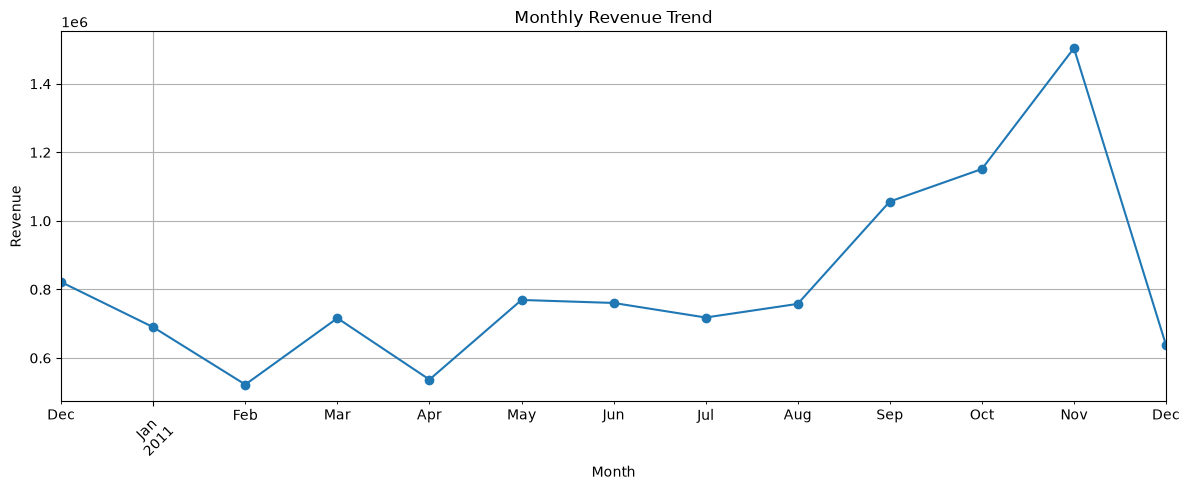

Monthly revenue:
YearMonth
2010-12     821452.730
2011-01     689811.610
2011-02     522545.560
2011-03     716215.260
2011-04     536968.491
2011-05     769296.610
2011-06     760547.010
2011-07     718076.121
2011-08     757841.380
2011-09    1056435.192
2011-10    1151263.730
2011-11    1503866.780
2011-12     637790.330
Freq: M, Name: Revenue, dtype: float64


In [41]:
# Extract year and month
sales_df["YearMonth"] = sales_df["InvoiceDate"].dt.to_period("M")

# Calculate monthly revenue
monthly_revenue = (
    sales_df.groupby("YearMonth")["Revenue"]
    .sum()
)

# Visualize the trend
plt.figure(figsize=(12, 5))
monthly_revenue.plot(kind="line", marker="o")

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

print("Monthly revenue:")
print(monthly_revenue)

In [42]:
# Customer-level analysis: only records with known customer IDs
customer_df = sales_df.dropna(subset=["CustomerID"]).copy()

customer_summary = (
    customer_df.groupby("CustomerID")
    .agg(
        TotalRevenue=("Revenue", "sum"),
        TotalOrders=("InvoiceNo", "nunique"),
        TotalItems=("Quantity", "sum")
    )
)

# Top 10 customers by revenue
top_customers = customer_summary.sort_values(
    "TotalRevenue", ascending=False
).head(10)

print("Top 10 customers by revenue:")
print(top_customers.round(2))

# Summary of customer purchasing behaviour
print("\nCustomer summary:")
print(customer_summary[["TotalRevenue", "TotalOrders", "TotalItems"]].describe().round(2))

Top 10 customers by revenue:
            TotalRevenue  TotalOrders  TotalItems
CustomerID                                       
14646.0        280206.02           73      196915
18102.0        259657.30           60       64124
17450.0        194390.79           46       69973
16446.0        168472.50            2       80997
14911.0        143711.17          201       80240
12415.0        124914.53           21       77374
14156.0        117210.08           55       57768
17511.0         91062.38           31       64549
16029.0         80850.84           63       40108
12346.0         77183.60            1       74215

Customer summary:
       TotalRevenue  TotalOrders  TotalItems
count       4338.00      4338.00     4338.00
mean        2048.69         4.27     1187.64
std         8985.23         7.70     5043.62
min            3.75         1.00        1.00
25%          306.48         1.00      159.00
50%          668.57         2.00      378.00
75%         1660.60         5.00     